# EMBER2024: primary data and feature analysis

- **This milestone:** understand the inputs and propose feature subsets. No classifier training or evaluation.
- Analyze the files actually present: currently Win64 train/test features plus the challenge set.
- Use fitting data for normalization, feature selection and PCA. Historical scores are references only.

In [1]:
# Import analysis tools
# Limit numerical threads so the notebook stays responsive.

from pathlib import Path
import json, hashlib, platform, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

thread_limits = threadpool_limits(limits=4)
from multi_label_static_analysis.config import project_paths
from multi_label_static_analysis.data_analysis import (
    stream_metadata,
    common_extractors,
    vectorize_record,
    feature_dictionary,
    binary_anova,
    verify_score_reference,
    assert_no_models,
)


In [2]:
# Choose paths and settings
# Use the TOML paths; keep the seed and display settings together.

P = project_paths()
DATA = P.data
REPORT = P.reports
ART = P.artifacts
REPORT.mkdir(parents=True, exist_ok=True)
(REPORT / "figures").mkdir(exist_ok=True)
SEED = 603
rng = np.random.default_rng(SEED)
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)


In [3]:
# Define output helpers
# Each plot is saved before display; each table is exported before display.

def savefig(name):
    plt.tight_layout()
    plt.savefig(REPORT / "figures" / name, dpi=150, bbox_inches="tight")
    plt.show()


def table(frame, name):
    frame.to_csv(REPORT / name, index=False)
    display(frame)


In [4]:
# Check inputs and historical references
# Fail early if classifier artifacts remain or preserved scores changed.

assert_no_models(ART)
score_reference = verify_score_reference(P.historical)
paths = sorted(DATA.glob("*.jsonl"))
assert paths, "Extract feature JSONL files first."
print(
    "Data files:",
    len(paths),
    "source GB:",
    round(sum(p.stat().st_size for p in paths) / 1e9, 2),
)
print("Current environment:", platform.python_version())
print("Historical score files protected by SHA256:", len(score_reference["files"]))
print(
    "PASS: inputs present, no trained models retained, historical score checksums verified."
)


Data files: 128 source GB: 33.71
Current environment: 3.14.7
Historical score files protected by SHA256: 1
PASS: inputs present, no trained models retained, historical score checksums verified.


## 2. Ingest and inspect the raw data

Read every JSONL record once. Export schema, missingness and source audits before proceeding. Raw counts still include duplicates.

In [5]:
# Ingest metadata once
# Stream raw JSONL rather than retaining complete feature records in RAM.

rows, source_profile, source_sha, schema_issues, parse_errors = stream_metadata(paths)
raw = pd.DataFrame(rows)
del rows


Ingested 32 of 128 files; 322581 metadata rows


Ingested 64 of 128 files; 644275 metadata rows


Ingested 96 of 128 files; 965084 metadata rows


Ingested 128 of 128 files; 1286315 metadata rows


In [6]:
# Normalize metadata types
# Unparseable values remain visible as missing values for the audit.

raw["date"] = pd.to_datetime(raw.timestamp, unit="s", utc=True, errors="coerce")
raw["family_confidence"] = pd.to_numeric(raw.family_confidence, errors="coerce")
raw["file_size"] = pd.to_numeric(raw.file_size, errors="coerce")
raw["byte_entropy"] = pd.to_numeric(raw.byte_entropy, errors="coerce")


In [7]:
# Export the source inventory
# Keep source filenames, sizes and row counts as provenance.

inventory = pd.DataFrame(source_profile)
inventory.assign(file_types=inventory.file_types.map(json.dumps)).to_csv(
    REPORT / "source_inventory.csv", index=False
)


In [8]:
# Summarize schema quality
# Record problems before allowing vectorization to continue.

quality = {
    "raw_rows": len(raw),
    "files": len(paths),
    "source_records_sha256": source_sha,
    "parse_errors": len(parse_errors),
    "schema_issues": schema_issues,
    "missing_dates": int(raw.date.isna().sum()),
    "missing_identity": int(raw.sha256.isna().sum()),
    "invalid_binary_labels": int((~raw.malicious.isin([0, 1])).sum()),
    "missing_family": int(raw.family.isna().sum()),
    "empty_behavior_lists": int(raw.tags.map(len).eq(0).sum()),
}
(REPORT / "ingestion_quality.json").write_text(json.dumps(quality, indent=2))
display(pd.Series(quality, dtype=object))


raw_rows                                                           1286315
files                                                                  128
source_records_sha256    dbe242c0a67b976abb8b35e35a4a0fdec648e11a3c3451...
parse_errors                                                             0
schema_issues                                                           {}
missing_dates                                                            0
missing_identity                                                         0
invalid_binary_labels                                                    0
missing_family                                                      774985
empty_behavior_lists                                               1038679
dtype: object

In [9]:
# Inspect the raw population
# These counts include duplicates; they are not modeling counts.

table(
    raw.groupby(["official", "file_type"]).size().rename("raw_rows").reset_index(),
    "raw_population.csv",
)
assert (
    not parse_errors and not schema_issues
), "Review raw schema errors before vectorization."
assert raw.date.notna().all() and raw.malicious.isin([0, 1]).all()
print("PASS: every raw record ingested; schema, labels and timestamps audited.")


,official,file_type,raw_rows
0,challenge,APK,256
1,challenge,Dot_Net,829
2,challenge,ELF,386
3,challenge,PDF,805
4,challenge,Win32,3225
5,challenge,Win64,814
6,test,Win64,240000
7,train,Win64,1040000


PASS: every raw record ingested; schema, labels and timestamps audited.


## 3. Check identities and time boundaries

- Report duplicate identities and annotation disagreements.
- Split official training into fitting, validation and calibration periods.
- Purge later exact TLSH matches. Fuzzy and family-disjoint grouping remain future work.

In [10]:
# Measure identity duplication
# Check annotation disagreement before selecting a representative record.

duplicate_counts = raw.groupby("sha256", sort=False).size()
conflicts = raw.groupby("sha256", sort=False).agg(
    binary_versions=("malicious", "nunique"),
    behavior_versions=("tags", "nunique"),
    official_partitions=("official", "nunique"),
)
conflict_summary = {
    "repeated_identities": int((duplicate_counts > 1).sum()),
    "repeated_rows": int(raw.sha256.duplicated().sum()),
    "binary_conflict_identities": int(conflicts.binary_versions.gt(1).sum()),
    "behavior_conflict_identities": int(conflicts.behavior_versions.gt(1).sum()),
    "cross_official_identity_groups": int(conflicts.official_partitions.gt(1).sum()),
}
conflicts.query("binary_versions > 1 or behavior_versions > 1").head(
    100
).reset_index().to_csv(REPORT / "duplicate_conflict_examples.csv", index=False)
(REPORT / "duplicate_audit.json").write_text(json.dumps(conflict_summary, indent=2))
display(pd.Series(conflict_summary))


repeated_identities               639993
repeated_rows                     640007
binary_conflict_identities             0
behavior_conflict_identities           0
cross_official_identity_groups         0
dtype: int64

In [11]:
# Define chronological windows
# Partition by record timestamps, not filename week strings.

train_end = raw.loc[raw.official.eq("train"), "date"].max().normalize() + pd.Timedelta(
    days=1
)
val_start = train_end - pd.Timedelta(weeks=12)
cal_start = train_end - pd.Timedelta(weeks=6)
raw["split"] = raw.official
raw.loc[raw.official.eq("train") & raw.date.ge(val_start), "split"] = "validation"
raw.loc[raw.official.eq("train") & raw.date.ge(cal_start), "split"] = "calibration"
raw.loc[raw.split.eq("train"), "split"] = "fit"


In [12]:
# Retain canonical identities
# Keep the existing earliest-record policy so vector-cache row identities match.

meta = (
    raw.sort_values(["date", "sha256", "source", "line"])
    .drop_duplicates("sha256", keep="first")
    .copy()
)
del raw, conflicts, duplicate_counts


In [13]:
# Remove later exact-TLSH matches
# A similar group must not cross into a later evaluation partition.

order = {"fit": 0, "validation": 1, "calibration": 2, "test": 3, "challenge": 4}
meta["priority"] = meta.split.map(order)
valid_tlsh = meta.tlsh.notna() & ~meta.tlsh.isin(["", "TNULL", "NULL", "-"])
first_group = meta.loc[valid_tlsh].groupby("tlsh").priority.min()
later = valid_tlsh & meta.priority.gt(meta.tlsh.map(first_group))
tlsh_purged = int(later.sum())
meta = meta.loc[~later].reset_index(drop=True)
meta["row_id"] = np.arange(len(meta))


In [14]:
# Check split separation
# Check chronology and identity grouping before analyzing features.

assert meta.sha256.is_unique
for a, b in [
    ("fit", "validation"),
    ("validation", "calibration"),
    ("calibration", "test"),
]:
    assert (
        meta.loc[meta.split.eq(a), "date"].max()
        < meta.loc[meta.split.eq(b), "date"].min()
    )
v = meta.tlsh.notna() & ~meta.tlsh.isin(["", "TNULL", "NULL", "-"])
assert meta.loc[v].groupby("tlsh").split.nunique().max() == 1


In [15]:
# Export the retained population
# Report the effect of the exact-match controls.

split_summary = (
    meta.groupby(["split", "file_type"])
    .agg(n=("sha256", "size"), start=("date", "min"), end=("date", "max"))
    .reset_index()
)
split_summary.to_csv(REPORT / "chronological_population.csv", index=False)
display(split_summary)
print("Exact TLSH cross-partition purges:", tlsh_purged)


,split,file_type,n,start,end
0,calibration,Win64,59929,2024-08-11 00:00:21+00:00,2024-09-21 23:59:41+00:00
1,challenge,APK,256,2023-12-22 09:00:50+00:00,2024-12-11 13:48:42+00:00
2,challenge,Dot_Net,829,2023-09-24 00:07:35+00:00,2024-12-11 23:27:51+00:00
3,challenge,ELF,386,2023-09-25 02:44:17+00:00,2024-12-06 14:24:45+00:00
4,challenge,PDF,805,2023-09-24 17:33:51+00:00,2024-12-11 16:37:28+00:00
5,challenge,Win32,3225,2023-09-24 06:15:57+00:00,2024-12-11 19:25:38+00:00
6,challenge,Win64,812,2023-09-25 02:55:53+00:00,2024-12-11 17:17:51+00:00
7,fit,Win64,400000,2023-09-24 00:01:40+00:00,2024-06-29 23:59:43+00:00
8,test,Win64,119895,2024-09-22 00:01:48+00:00,2024-12-14 23:59:37+00:00
9,validation,Win64,59945,2024-06-30 00:00:01+00:00,2024-08-10 23:59:42+00:00


Exact TLSH cross-partition purges: 226


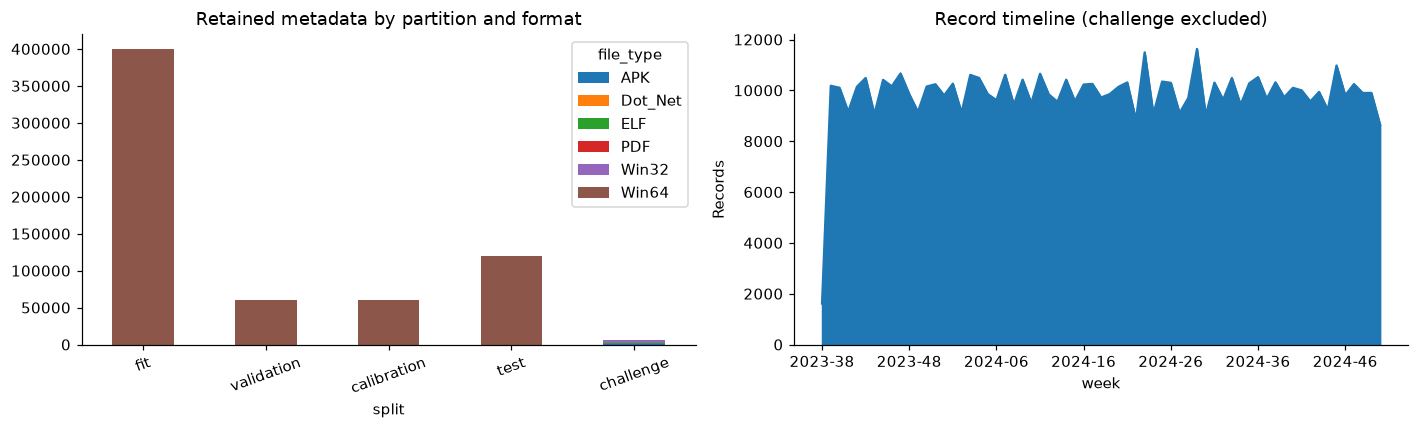

PASS: unique identities and time-forward partitions verified; exact TLSH overlaps purged.


In [16]:
# Plot population and collection time
# Keep this figure complete inside one cell so it cannot render halfway through.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
meta.groupby(["split", "file_type"]).size().unstack(fill_value=0).reindex(
    order
).plot.bar(
    stacked=True, ax=axes[0], rot=20, title="Retained metadata by partition and format"
)
weekly = (
    meta[meta.official.ne("challenge")]
    .assign(week=meta.date.dt.strftime("%G-%V"))
    .groupby(["week", "file_type"])
    .size()
    .unstack(fill_value=0)
)
weekly.plot.area(ax=axes[1], title="Record timeline (challenge excluded)", legend=False)
axes[1].set_ylabel("Records")
savefig("01_population_and_timeline.png")
print(
    "PASS: unique identities and time-forward partitions verified; exact TLSH overlaps purged."
)


## 4. Understand the labels

- Missing malware tags mean **unknown**, not verified negatives.
- Map explicit aliases only; check role support on fitting data.
- Family/confidence fields describe annotation quality and stay outside the input vectors.

In [17]:
# Declare the role aliases
# Only explicit aliases map to the proposed roles; do not invent missing labels.

ALIASES = {
    "Ransomware": {"ransomware", "ransom"},
    "Infostealer": {"infostealer", "stealer", "pws", "passwordstealer"},
    "Stager": {"downloader", "dropper", "loader"},
    "Remote Access Trojan": {"backdoor", "rat", "remoteaccess"},
    "Botnet Agent": {"botnet", "bot"},
    "Banking Trojan": {"banker", "banking", "bankingtrojan"},
    "Cryptominer": {"miner", "coinminer", "cryptominer", "cryptocurrencyminer"},
}


In [18]:
# Create label masks
# Separate unknown behavior annotations from observed negatives.

LABELS = list(ALIASES)
Y = np.array(
    [[int(bool(set(tags) & ALIASES[label])) for label in LABELS] for tags in meta.tags],
    dtype=np.int8,
)
y = meta.malicious.to_numpy(dtype=np.int8)
annotated = meta.tags.map(len).gt(0).to_numpy()
fit = meta.split.eq("fit").to_numpy()
observed = (y == 0) | annotated
mal_annotated = fit & (y == 1) & annotated


In [19]:
# Measure fitting support
# Eligibility is based on fitting-period labels only.

support = pd.DataFrame(
    {
        "category": LABELS,
        "fit_positive": Y[fit & observed].sum(axis=0),
        "conditional_negative": int(mal_annotated.sum()) - Y[mal_annotated].sum(axis=0),
    }
)
supported = (support.fit_positive.to_numpy() >= 20) & (
    support.conditional_negative.to_numpy() >= 20
)
support["supported_for_future_study"] = supported
table(support, "label_support.csv")


,category,fit_positive,conditional_negative,supported_for_future_study
0,Ransomware,760,97928,True
1,Infostealer,7520,91168,True
2,Stager,3900,94788,True
3,Remote Access Trojan,1341,97347,True
4,Botnet Agent,0,98688,False
5,Banking Trojan,100,98588,True
6,Cryptominer,27989,70699,True


In [20]:
# Inspect annotation coverage
# Missing behavior tags are a data-quality limitation, not benign behavior.

coverage = (
    meta[fit]
    .assign(annotated=annotated[fit])
    .groupby(["file_type", "malicious"])
    .agg(n=("sha256", "size"), annotation_rate=("annotated", "mean"))
    .reset_index()
)
table(coverage, "fitting_annotation_coverage.csv")


,file_type,malicious,n,annotation_rate
0,Win64,0,200000,0.00000
1,Win64,1,200000,0.49344


In [21]:
# Export observed tags and families
# Family and confidence are descriptive metadata, not vector inputs.

tag_counts = Counter(t for tags in meta.loc[fit, "tags"] for t in tags)
tag_table = pd.DataFrame(tag_counts.most_common(), columns=["tag", "count"])
tag_table.to_csv(REPORT / "fitting_behavior_tags.csv", index=False)
family_table = (
    meta.loc[fit, "family"]
    .value_counts(dropna=False)
    .rename_axis("family")
    .reset_index(name="n")
)
family_table.to_csv(REPORT / "fitting_families.csv", index=False)


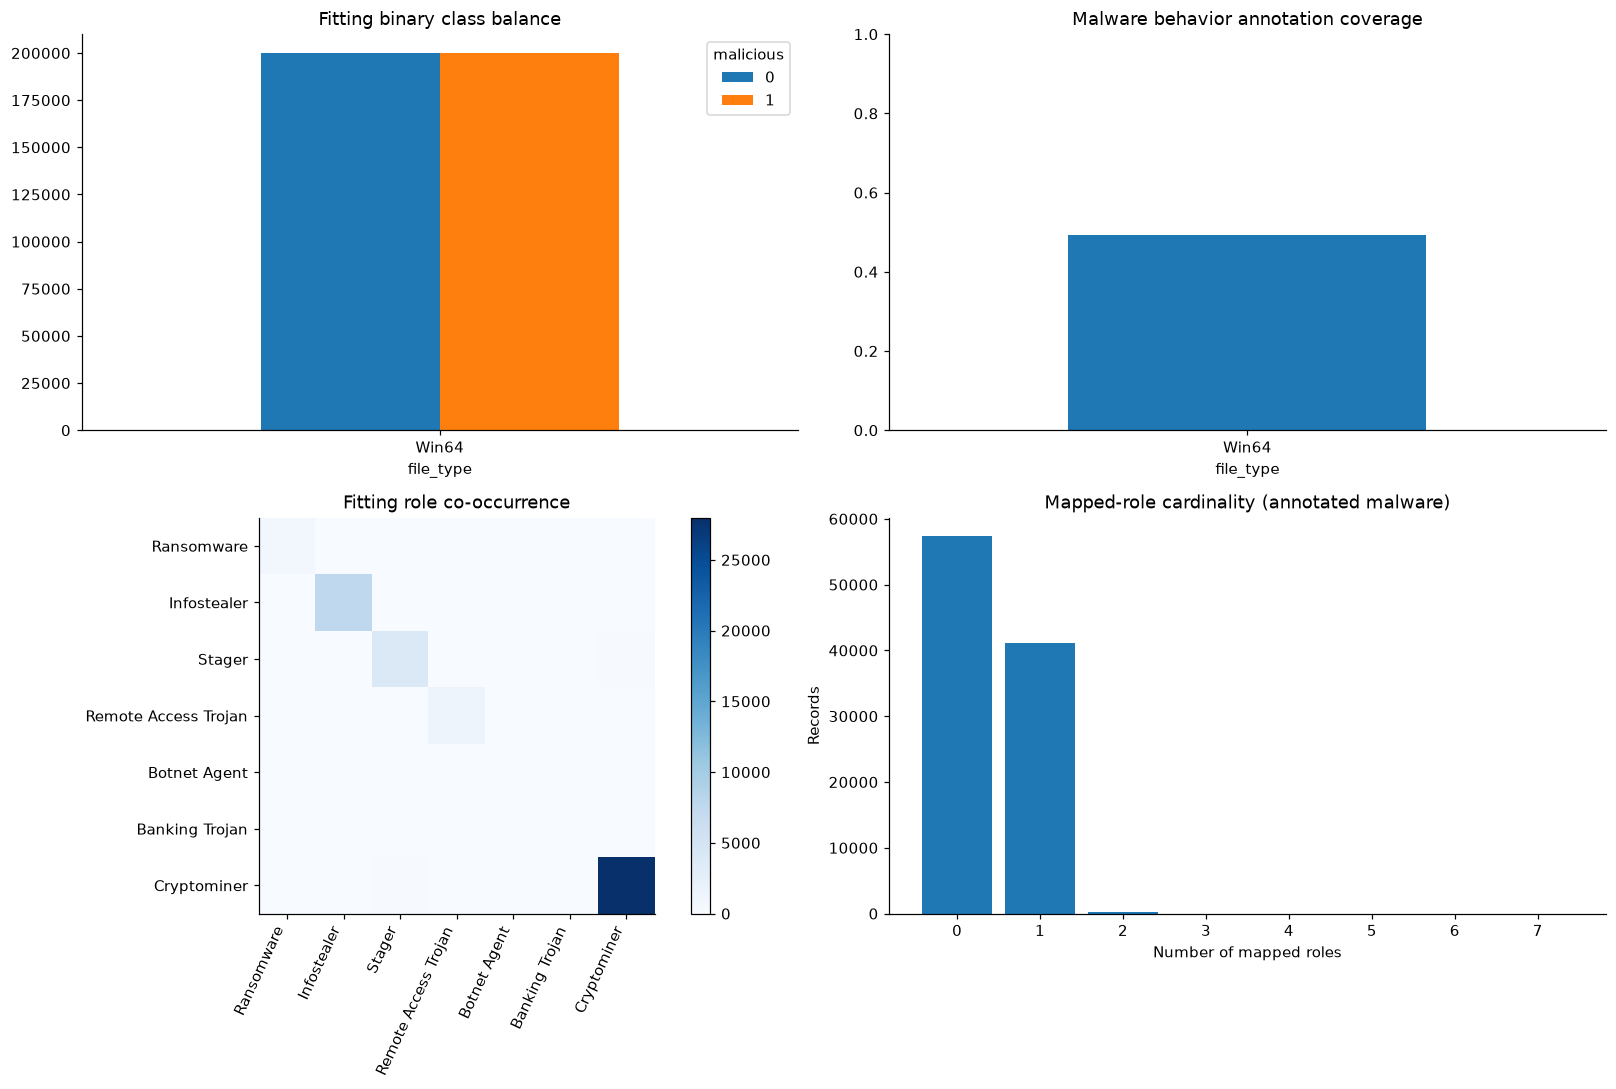

In [22]:
# Plot label quality
# The four panels use fitting data and share one consistent figure.

from multi_label_static_analysis.notebook_steps import plot_label_quality

plot_label_quality(meta, fit, coverage, Y, mal_annotated, LABELS, savefig)


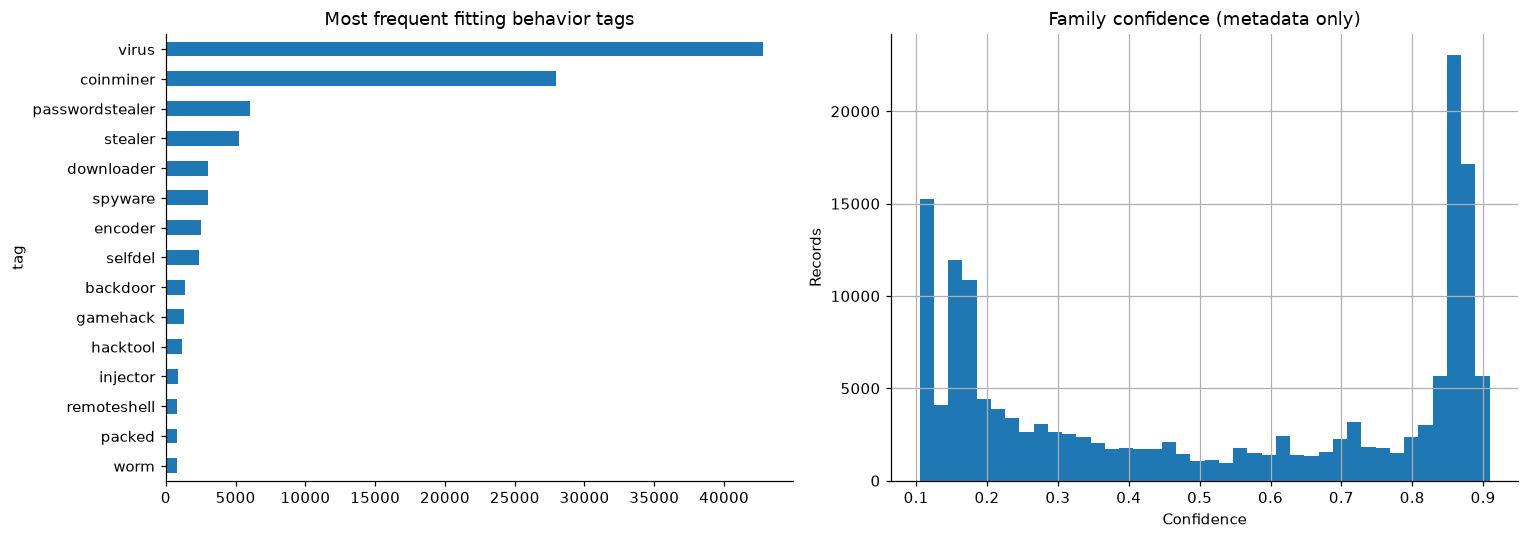

In [23]:
# Plot tag prevalence and confidence
# These plots describe annotation quality, not classifier performance.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tag_table.head(15).set_index("tag")["count"].sort_values().plot.barh(
    ax=axes[0], title="Most frequent fitting behavior tags"
)
meta.loc[fit, "family_confidence"].dropna().hist(bins=40, ax=axes[1])
axes[1].set(
    title="Family confidence (metadata only)", xlabel="Confidence", ylabel="Records"
)
savefig("03_tag_and_annotation_quality.png")


In [24]:
# Check the label-analysis milestone
# Report how much fitting malware lacks behavior annotations.

print("Unannotated fitting malware:", int((fit & (y == 1) & ~annotated).sum()))
print("PASS: role support and label-quality rules use fitting-period metadata only.")


Unannotated fitting malware: 101312
PASS: role support and label-quality rules use fitting-period metadata only.


## 5. Convert static features to inputs

Use the four shared thrember groups: general information, byte histogram, byte entropy and strings. Verify cache identity and raw-to-vector alignment. The 696-input representation omits PE-specific groups.

In [25]:
# Define the static input dictionary
# Only the four allowlisted static groups enter the numerical matrix.

from multi_label_static_analysis.thrember import features as feature_module

extractors = common_extractors()
names = feature_dictionary(extractors)
groups = {}
offset = 0
for ex in extractors:
    groups[ex.name] = list(range(offset, offset + ex.dim))
    offset += ex.dim
D = offset
assert D == 696 and len(set(names)) == D


/Users/satvik/Desktop/projects/multi-label-static-analysis/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [26]:
# Identify the input cache
# Reuse vectors only when source text, row identity and extractor hashes match.

feature_source_sha = hashlib.sha256(
    Path(feature_module.__file__).read_bytes()
).hexdigest()
key = hashlib.sha256(
    (
        source_sha + str(meta[["source", "line"]].values.tolist()) + feature_source_sha
    ).encode()
).hexdigest()
cache = ART / "static_features.npy"
keyfile = ART / "feature_cache_key.txt"


In [27]:
# Read or build the vector matrix
# A memory-mapped float32 matrix keeps the dataset within a bounded RAM budget.

if cache.exists() and keyfile.exists() and keyfile.read_text() == key:
    X = np.load(cache, mmap_mode="r")
    print("Reused source-verified input matrix:", X.shape)
else:
    X = np.lib.format.open_memmap(
        cache, mode="w+", dtype="float32", shape=(len(meta), D)
    )
    lookup = {(r.source, int(r.line)): int(r.row_id) for r in meta.itertuples()}
    n = 0
    for path in paths:
        with path.open() as stream:
            for line_no, line in enumerate(stream):
                i = lookup.get((path.name, line_no))
                if i is None:
                    continue
                X[i] = vectorize_record(json.loads(line), extractors)
                n += 1
    assert n == len(meta)
    X.flush()
    keyfile.write_text(key)
    del lookup
    print("Stream-vectorized", n, "records.")
assert X.shape == (len(meta), D)


Stream-vectorized 646082 records.


In [28]:
# Choose raw-to-vector checks
# Select representative source rows across all available formats.

checks = []
for ft in sorted(meta.file_type.unique()):
    part = meta[meta.file_type.eq(ft)]
    source = part.source.iloc[0]
    checks.extend(
        part[part.source.eq(source)]
        .head(6)[["source", "line", "row_id"]]
        .itertuples(index=False, name=None)
    )


In [29]:
# Group the checks by source file
# Avoid rereading the same file for every checked row.

check_map = {}
for source, line, i in checks:
    check_map.setdefault(source, {})[int(line)] = int(i)


In [30]:
# Check raw-to-vector alignment
# Regenerate selected rows independently to detect a misaligned cache.

checked = 0
for source, wanted in check_map.items():
    with (DATA / source).open() as stream:
        for line_no, line in enumerate(stream):
            if line_no in wanted:
                expected = vectorize_record(json.loads(line), extractors)
                assert np.allclose(expected, X[wanted[line_no]], equal_nan=True)
                checked += 1
            if line_no >= max(wanted):
                break
print("Raw-to-vector independent row checks:", checked)


Raw-to-vector independent row checks: 22


In [31]:
# Count invalid feature values
# Inspect vectors in small batches rather than allocating a full boolean matrix.

nonfinite = sum(
    int((~np.isfinite(X[start : start + 4096])).sum())
    for start in range(0, len(X), 4096)
)


In [32]:
# Purge later identical vectors
# Use no labels when enforcing this conservative duplicate control.

vector_groups = {}
keep = np.ones(len(meta), dtype=bool)
for i in np.argsort(meta.priority.to_numpy(), kind="stable"):
    signature = hashlib.blake2b(
        np.nan_to_num(X[i], nan=-1).tobytes(), digest_size=16
    ).digest()
    previous = vector_groups.setdefault(signature, meta.split.iloc[i])
    if previous != meta.split.iloc[i]:
        keep[i] = False
idx = {s: np.flatnonzero(meta.split.eq(s).to_numpy() & keep) for s in order}
del vector_groups
assert all(len(idx[s]) for s in order)


In [33]:
# Export semantic feature names
# Keep categorical byte fields distinct from continuous measurements.

dictionary = pd.DataFrame(
    {"index": range(D), "feature": names, "group": [n.split(".")[0] for n in names]}
)
dictionary["kind"] = "continuous"
dictionary.loc[
    dictionary.feature.isin(
        ["general.is_pe"] + [f"general.start_byte_{i}" for i in range(4)]
    ),
    "kind",
] = "categorical"
dictionary.to_csv(REPORT / "feature_dictionary.csv", index=False)


In [34]:
# Inspect eligible partition sizes
# These are the records left after all vector-level controls.

counts = meta.loc[keep].groupby(["split", "file_type"]).size().rename("n").reset_index()
table(counts, "eligible_partition_counts.csv")


,split,file_type,n
0,calibration,Win64,59929
1,challenge,APK,256
2,challenge,Dot_Net,829
3,challenge,ELF,386
4,challenge,PDF,805
5,challenge,Win32,3225
6,challenge,Win64,812
7,fit,Win64,400000
8,test,Win64,119892
9,validation,Win64,59945


In [35]:
# Save vectorization provenance
# Record input shape, cache identity and independent-check coverage.

vector_quality = {
    "rows": len(meta),
    "features": D,
    "nonfinite_cells": nonfinite,
    "vector_purges": int((~keep).sum()),
    "independent_row_checks": checked,
    "feature_cache_key": key,
    "extractor_sha256": feature_source_sha,
}
(REPORT / "vectorization_quality.json").write_text(json.dumps(vector_quality, indent=2));


In [36]:
# Check histogram normalization
# Frequency groups should sum to one; no classifier is involved.

probe = idx["fit"][:10000]
for group in ["histogram", "byteentropy"]:
    total = np.nansum(X[np.ix_(probe, groups[group])], axis=1)
    assert np.allclose(total, 1, atol=1e-5)
assert_no_models(ART)
print(
    "PASS: static-only 696-column inputs, semantic names, cache alignment and histogram normalization checked."
)


PASS: static-only 696-column inputs, semantic names, cache alignment and histogram normalization checked.


## 6. Inspect feature quality

Calculate exact fitting statistics in small column blocks. Look for missing values, constants, sparsity and long tails before choosing transforms.

In [37]:
# Compute exact fitting statistics
# Process 16 columns at a time over every eligible fitting record.

from multi_label_static_analysis.notebook_steps import fitting_statistics

stat_records = fitting_statistics(X, idx, D, names)


In [38]:
# Export feature-quality tables
# Identify constants and long tails using fitting data only.

stats = pd.DataFrame(stat_records)
stats["constant"] = stats["std"].eq(0)
stats.to_csv(REPORT / "fitting_feature_statistics.csv", index=False)
variable = np.flatnonzero(~stats.constant.to_numpy())
table(
    stats.groupby("group")
    .agg(
        dimensions=("index", "size"),
        constants=("constant", "sum"),
        mean_zero_rate=("zero_rate", "mean"),
    )
    .reset_index(),
    "feature_group_summary.csv",
)
display(
    stats.sort_values("skewness", ascending=False).head(12)[
        ["feature", "median", "p99", "skewness", "zero_rate"]
    ]
)


,group,dimensions,constants,mean_zero_rate
0,byteentropy,256,0,0.268681
1,general,7,0,0.143118
2,histogram,256,0,0.003076
3,strings,177,1,0.303566


,feature,median,p99,skewness,zero_rate
669,strings.count.ipv6_addr,0.000000,83.000000,525.656961,0.622533
678,strings.count.post,0.000000,0.000000,523.922610,0.996605
625,strings.count./proc/,0.000000,0.000000,523.401774,0.992180
274,byteentropy.entropy_00.bytebin_11,0.000000,0.000022,520.736914,0.833825
654,strings.count.environment,2.000000,74.000000,478.902181,0.269498
664,strings.count.http://,1.000000,185.000000,445.354280,0.419780
692,strings.count.url,1.000000,230.000000,438.889187,0.398150
288,byteentropy.entropy_01.bytebin_09,0.000000,0.000071,432.804812,0.689072
665,strings.count.https://,0.000000,73.000000,431.348271,0.681390
659,strings.count.get,0.000000,0.000000,425.125949,0.991152


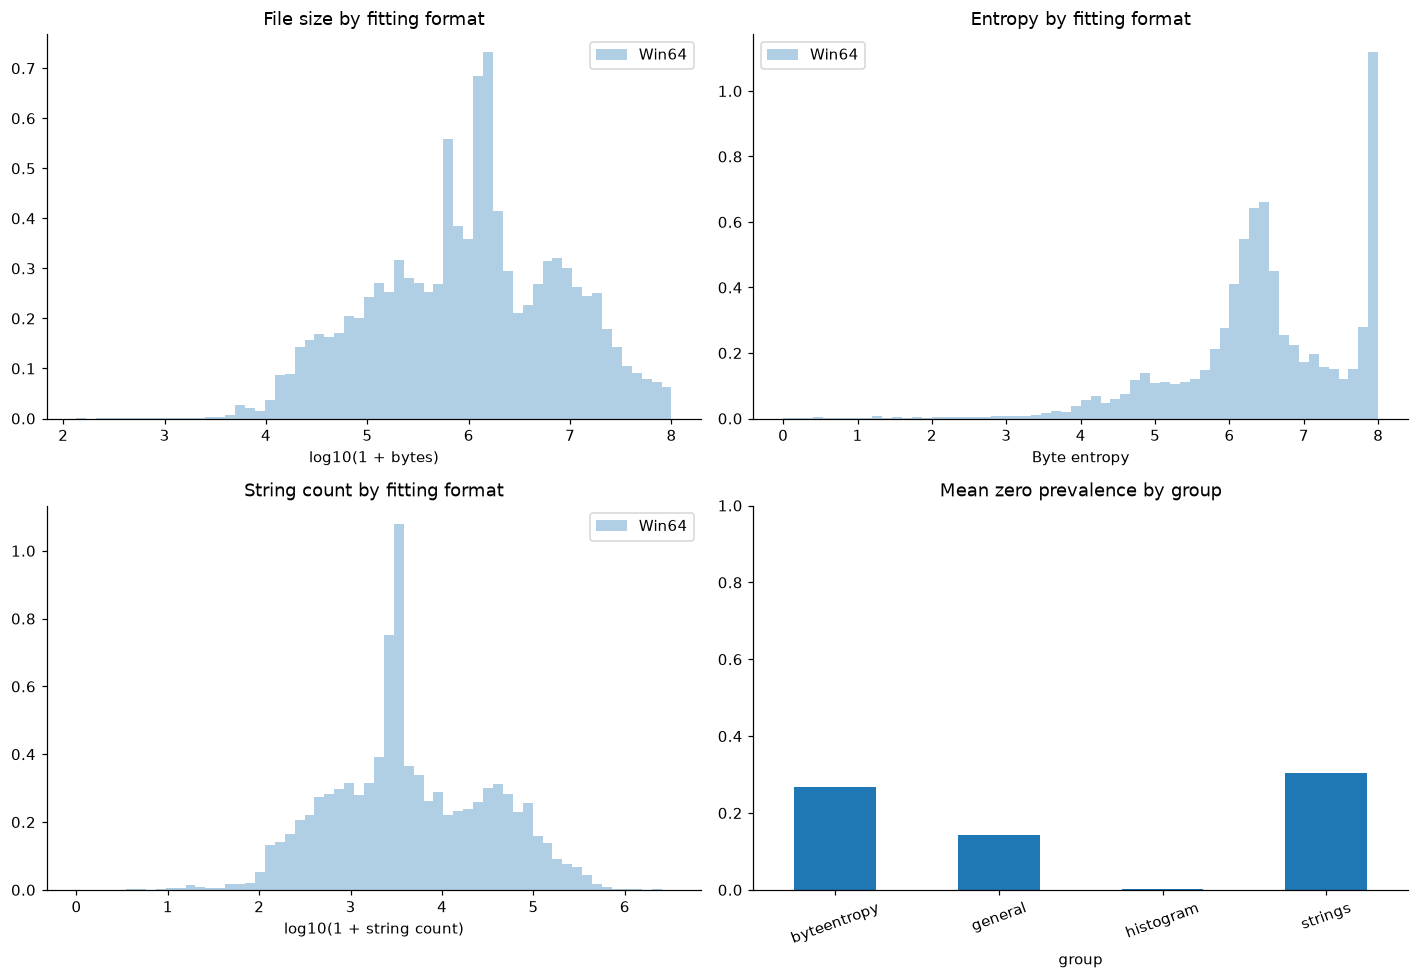

In [39]:
# Plot fitting distributions
# Use the same transforms and axes for each fitting format.

from multi_label_static_analysis.notebook_steps import plot_feature_distributions

plot_feature_distributions(meta, idx, X, groups, stats, savefig)


In [40]:
# Check the feature-statistics milestone
# Constants are reported, not silently discarded from the source matrix.

print(
    "Variable fitting columns:",
    len(variable),
    "constant columns:",
    int(stats.constant.sum()),
)
print(
    "PASS: exact full-fitting feature statistics computed without materializing the complete matrix."
)


Variable fitting columns: 695 constant columns: 1
PASS: exact full-fitting feature statistics computed without materializing the complete matrix.


## 7. Check scales and redundancy

Normalization uses full fitting statistics. Correlations use a reproducible 20,000-row fitting sample and can be sensitive to outliers.

In [41]:
# Select a reproducible fitting sample
# Correlation uses a hash sample; normalization statistics still use all fitting rows.

hash_order = sorted(
    idx["fit"],
    key=lambda i: hashlib.sha256((str(SEED) + meta.sha256.iloc[i]).encode()).digest(),
)
sample_idx = np.array(hash_order[:20000])
medians = stats["median"].to_numpy()
means = stats["mean"].to_numpy()
scales = stats["std"].to_numpy()


In [42]:
# Define fitting-only normalization
# Use fitting medians, means and scales; keep the source cache unchanged.

def standardized(ii):
    a = np.asarray(X[ii], dtype=np.float64)
    a = np.where(np.isfinite(a), a, medians)
    return ((a - means) / np.where(scales > 0, scales, 1))[:, variable]


Z = standardized(sample_idx)
assert np.isfinite(Z).all()


In [43]:
# Inspect feature redundancy
# Correlation is a sample-based association, not evidence of causality.

correlation = np.corrcoef(Z, rowvar=False)
upper = np.triu(np.abs(correlation), k=1)
left, right = np.where(upper >= 0.98)
pairs = pd.DataFrame(
    {
        "feature_a": [names[variable[i]] for i in left],
        "feature_b": [names[variable[j]] for j in right],
        "abs_correlation": upper[left, right],
    }
)
pairs.sort_values("abs_correlation", ascending=False).to_csv(
    REPORT / "high_correlation_pairs.csv", index=False
)
print(
    "Correlation sample size:", len(sample_idx), "pairs with |r| >= 0.98:", len(pairs)
)
display(pairs.sort_values("abs_correlation", ascending=False).head(15))


Correlation sample size: 20000 pairs with |r| >= 0.98: 76


,feature_a,feature_b,abs_correlation
75,strings.count.email_addr,strings.count.mac_addr,1.000000
0,general.start_byte_0,general.start_byte_1,1.000000
1,byteentropy.entropy_07.bytebin_04,byteentropy.entropy_07.bytebin_05,0.997792
60,byteentropy.entropy_15.bytebin_09,byteentropy.entropy_15.bytebin_10,0.997757
63,byteentropy.entropy_15.bytebin_09,byteentropy.entropy_15.bytebin_13,0.996918
4,byteentropy.entropy_07.bytebin_06,byteentropy.entropy_07.bytebin_07,0.996773
74,byteentropy.entropy_15.bytebin_13,byteentropy.entropy_15.bytebin_14,0.996742
68,byteentropy.entropy_15.bytebin_10,byteentropy.entropy_15.bytebin_14,0.996514
67,byteentropy.entropy_15.bytebin_10,byteentropy.entropy_15.bytebin_13,0.996488
64,byteentropy.entropy_15.bytebin_09,byteentropy.entropy_15.bytebin_14,0.996319


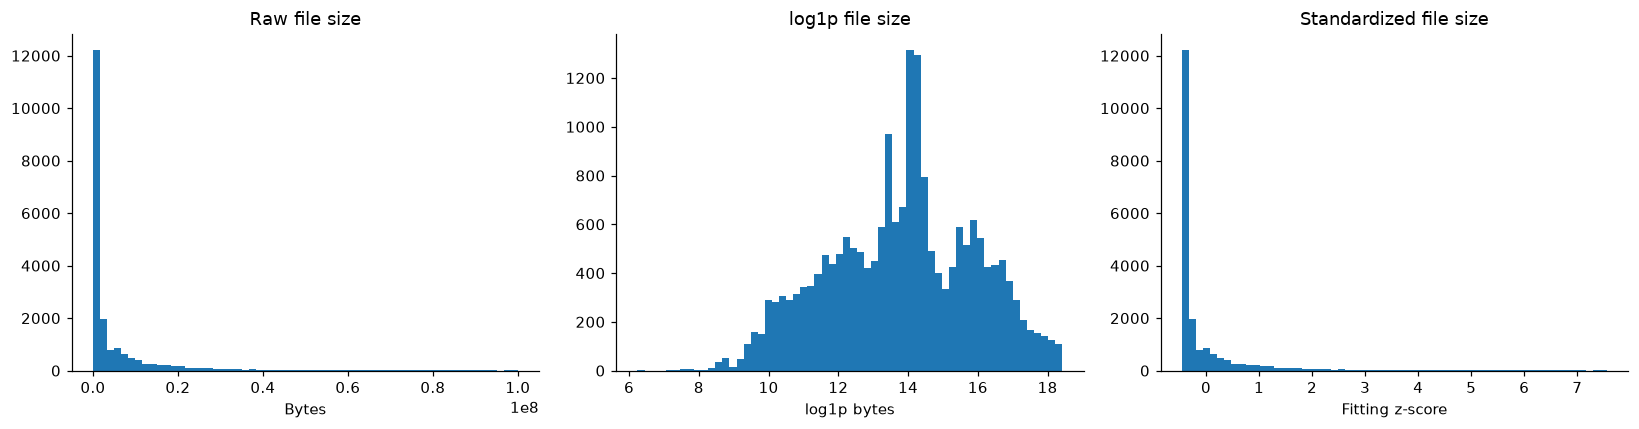

In [44]:
# Compare raw and transformed size
# Log scaling and standardization are diagnostics, not selected preprocessing winners.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(X[sample_idx, 0], bins=60)
axes[0].set(title="Raw file size", xlabel="Bytes")
axes[1].hist(np.log1p(X[sample_idx, 0]), bins=60)
axes[1].set(title="log1p file size", xlabel="log1p bytes")
axes[2].hist(Z[:, np.flatnonzero(variable == 0)[0]], bins=60)
axes[2].set(title="Standardized file size", xlabel="Fitting z-score")
savefig("05_normalization_and_tails.png")


In [45]:
# Check normalization boundaries
# No validation or held-out values determine the normalization statistics.

print(
    "PASS: normalization derives only from fitting statistics; constant filtering and redundancy audit complete."
)


PASS: normalization derives only from fitting statistics; constant filtering and redundancy audit complete.


## 8. Propose feature subsets

- Full-fitting ANOVA and sampled MI measure association, not predictive accuracy.
- Treat unobserved tags as unknown and skip unsupported roles.
- Export candidate subsets; choosing a winner requires a later supervised experiment.

In [46]:
# Choose observed fitting targets
# Skip unsupported roles; category comparisons use annotated malware only.

roles = {"maliciousness": (np.ones(len(idx["fit"]), dtype=bool), y[idx["fit"]])}
for j, label in enumerate(LABELS):
    if supported[j]:
        roles[label] = (
            ((y[idx["fit"]] == 1) & annotated[idx["fit"]]),
            Y[idx["fit"], j],
        )


In [47]:
# Allocate univariate score arrays
# Keep one score per feature and target without fitting a classifier.

anova = {role: np.full(D, np.nan) for role in roles}
pvalues = {role: np.full(D, np.nan) for role in roles}


In [48]:
# Calculate exact ANOVA scores
# Use bounded blocks over the complete fitting period.

for start in range(0, D, 16):
    columns = np.arange(start, min(start + 16, D))
    a = np.asarray(X[np.ix_(idx["fit"], columns)], dtype=np.float64)
    a = np.where(np.isfinite(a), a, medians[columns])
    for role, (mask, target) in roles.items():
        f, p = binary_anova(a[mask], target[mask])
        anova[role][columns] = f
        pvalues[role][columns] = p
    del a


In [49]:
# Build an equal-target ranking
# Percentile ranks prevent a common role from dominating through raw score magnitude.

ranking = dictionary.copy()
for role in roles:
    ranking["F_" + role] = anova[role]
    ranking["p_" + role] = pvalues[role]
percentile = pd.DataFrame(
    {role: pd.Series(v).rank(pct=True).fillna(0) for role, v in anova.items()}
)
ranking["consensus_rank"] = percentile.mean(axis=1)


In [50]:
# Estimate mutual information
# Use a smaller fixed fitting sample because MI estimation is more expensive.

from sklearn.feature_selection import mutual_info_classif

mi_idx = np.array(hash_order[:6000])
mi_input = np.asarray(X[np.ix_(mi_idx, variable)], dtype=np.float64)
mi_input = np.where(np.isfinite(mi_input), mi_input, medians[variable])
discrete = np.isin(variable, [2, 3, 4, 5, 6])
ranking["MI_maliciousness"] = np.nan
ranking.loc[variable, "MI_maliciousness"] = mutual_info_classif(
    mi_input, y[mi_idx], discrete_features=discrete, random_state=SEED
)
del mi_input


In [51]:
# Export the feature rankings
# These associations are exploratory and have not been classifier-validated.

ranking["constant"] = stats.constant.to_numpy()
ranking = ranking.sort_values("consensus_rank", ascending=False)
ranking.to_csv(REPORT / "feature_selection_ranking.csv", index=False)


In [52]:
# Build a redundancy-pruned candidate
# Retain a representative high-ranked feature from strongly correlated groups.

eligible = ranking.loc[~ranking.constant, "index"].to_list()
position = {int(j): k for k, j in enumerate(variable)}
pruned = []
for j in eligible:
    if (
        not pruned
        or np.max(np.abs(correlation[position[j], [position[k] for k in pruned]]))
        < 0.98
    ):
        pruned.append(j)


In [53]:
# Save proposed feature subsets
# Top-64/128/256 subsets are candidates for a later controlled experiment.

candidates = {f"top_{k}": eligible[:k] for k in [64, 128, 256]}
candidates["correlation_pruned"] = pruned
selection = {
    "status": "exploratory filter subsets; not classifier-validated",
    "fitting_records": len(idx["fit"]),
    "category_records": int(mal_annotated[meta.row_id.iloc[idx["fit"]]].sum()),
    "MI_sample_n": len(mi_idx),
    "targets": list(roles),
    "feature_cache_key": key,
    "candidates": {name: [names[j] for j in ids] for name, ids in candidates.items()},
}
(REPORT / "candidate_feature_subsets.json").write_text(json.dumps(selection, indent=2));


In [54]:
# Inspect the top-ranked inputs
# Use semantic names so each proposed input can be reviewed.

display(
    ranking[["index", "feature", "group", "consensus_rank", "MI_maliciousness"]].head(
        20
    )
)


,index,feature,group,consensus_rank,MI_maliciousness
564,564,strings.printable_074,strings,0.922477,0.257894
579,579,strings.printable_089,strings,0.917726,0.259046
603,603,strings.printable_113,strings,0.915262,0.263822
565,565,strings.printable_075,strings,0.914015,0.234446
596,596,strings.printable_106,strings,0.913838,0.237572
138,138,histogram.byte_131,histogram,0.913434,0.171962
612,612,strings.printable_122,strings,0.913169,0.261562
129,129,histogram.byte_122,histogram,0.886551,0.267326
578,578,strings.printable_088,strings,0.885959,0.154308
8,8,histogram.byte_001,histogram,0.882409,0.217940


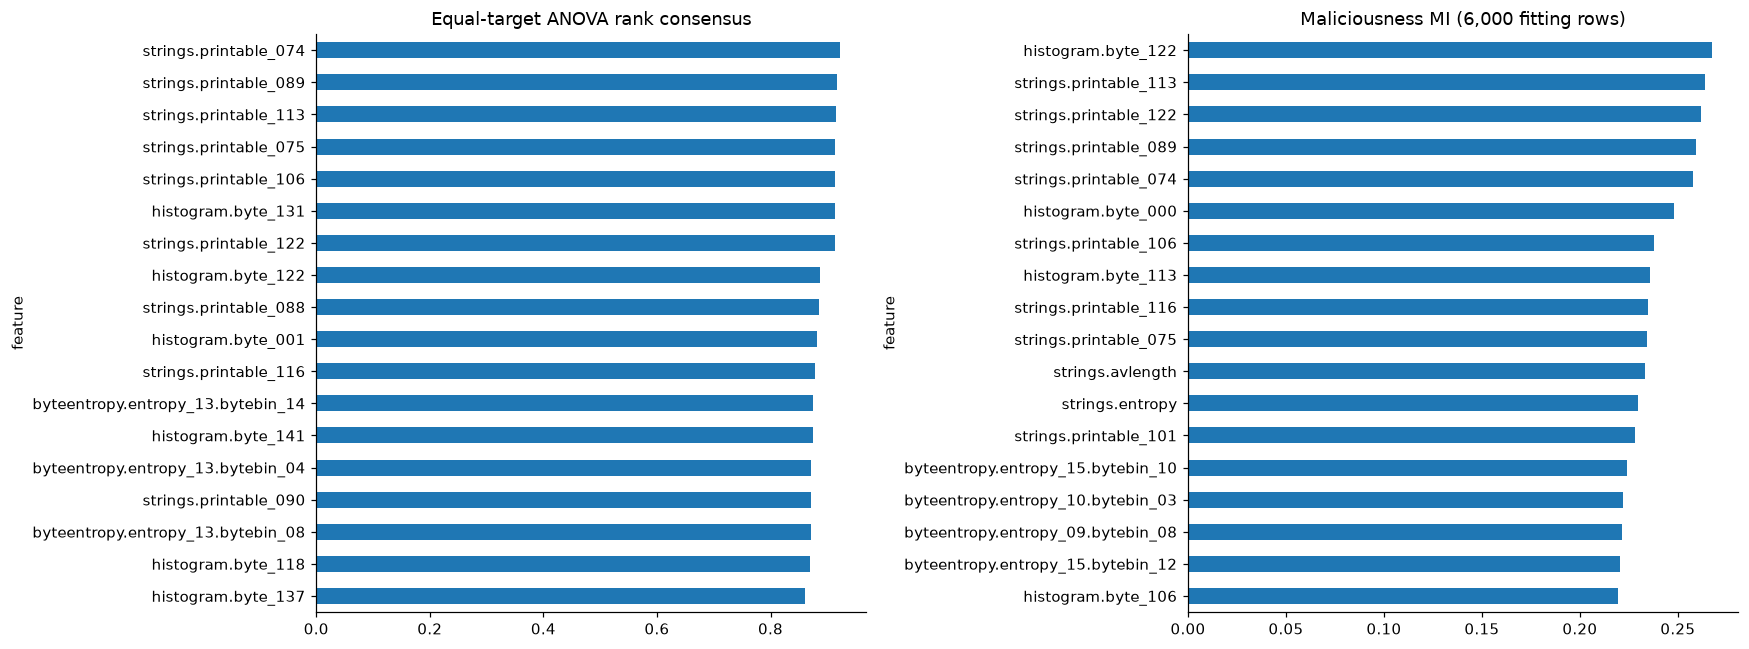

In [55]:
# Plot univariate rankings
# Compare the two association measures without treating either as accuracy.

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ranking[~ranking.constant].head(18).sort_values("consensus_rank").set_index(
    "feature"
).consensus_rank.plot.barh(ax=axes[0], title="Equal-target ANOVA rank consensus")
mi_top = (
    ranking.dropna(subset=["MI_maliciousness"])
    .nlargest(18, "MI_maliciousness")
    .sort_values("MI_maliciousness")
)
mi_top.set_index("feature").MI_maliciousness.plot.barh(
    ax=axes[1], title="Maliciousness MI (6,000 fitting rows)"
)
savefig("06_feature_rankings.png")


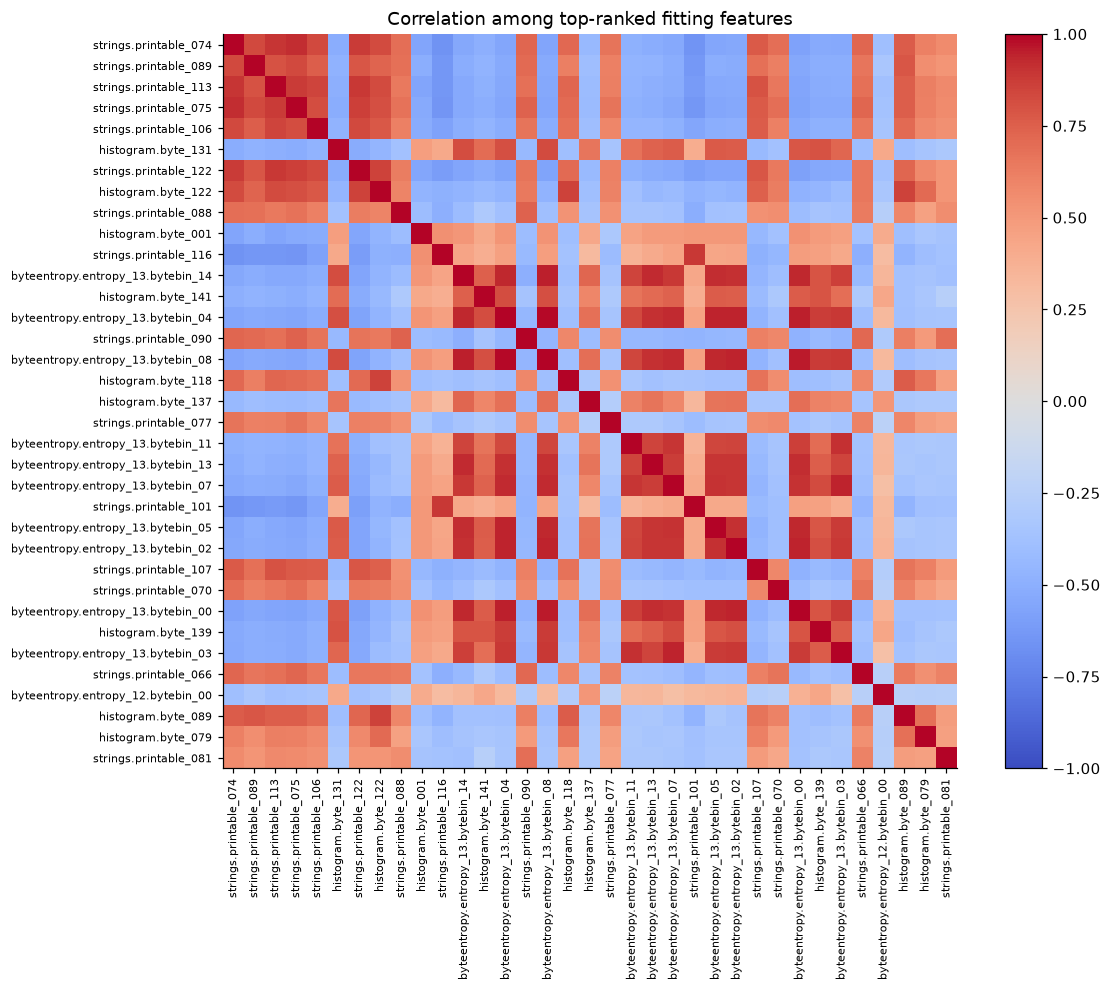

In [56]:
# Plot ranked-feature correlations
# Show where high-ranked inputs still carry overlapping information.

heat_features = eligible[:35]
positions = [position[j] for j in heat_features]
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(
    correlation[np.ix_(positions, positions)], vmin=-1, vmax=1, cmap="coolwarm"
)
ax.set_xticks(
    range(len(positions)), [names[j] for j in heat_features], rotation=90, fontsize=7
)
ax.set_yticks(range(len(positions)), [names[j] for j in heat_features], fontsize=7)
ax.set_title("Correlation among top-ranked fitting features")
fig.colorbar(im, ax=ax)
savefig("07_ranked_feature_correlation.png")


In [57]:
# Check candidate subsets
# Verify constants are excluded while keeping the decision provisional.

assert all(not stats.constant.iloc[j] for ids in candidates.values() for j in ids)
print("Correlation-pruned candidate dimensions:", len(pruned))
print(
    "PASS: fitting-only univariate rankings and candidate feature subsets exported; no classifier fit or score performed."
)


Correlation-pruned candidate dimensions: 678
PASS: fitting-only univariate rankings and candidate feature subsets exported; no classifier fit or score performed.


## 9. Explore variance with PCA

Fit PCA on normalized fitting inputs only. Labels are color overlays, never fitting inputs. Explained variance and visible clusters are not classifier scores.

In [58]:
# Fit PCA on fitting inputs
# Labels never enter the decomposition.

from sklearn.decomposition import PCA

pca = PCA(svd_solver="covariance_eigh").fit(Z)
explained = pd.DataFrame(
    {
        "component": np.arange(1, len(pca.explained_variance_ratio_) + 1),
        "variance_ratio": pca.explained_variance_ratio_,
    }
)
explained["cumulative_variance"] = explained.variance_ratio.cumsum()
explained.to_csv(REPORT / "pca_explained_variance.csv", index=False)


In [59]:
# Export projection evidence
# Retain variance and loading tables, not a serialized estimator.

components_needed = {
    str(q): int(np.searchsorted(explained.cumulative_variance.to_numpy(), q) + 1)
    for q in [0.9, 0.95, 0.99]
}
coordinates = (Z[:6000] - pca.mean_) @ pca.components_[:2].T
loadings = pd.DataFrame(
    {
        "feature": [names[j] for j in variable],
        "PC1": pca.components_[0],
        "PC2": pca.components_[1],
    }
)
loadings.to_csv(REPORT / "pca_loadings.csv", index=False)


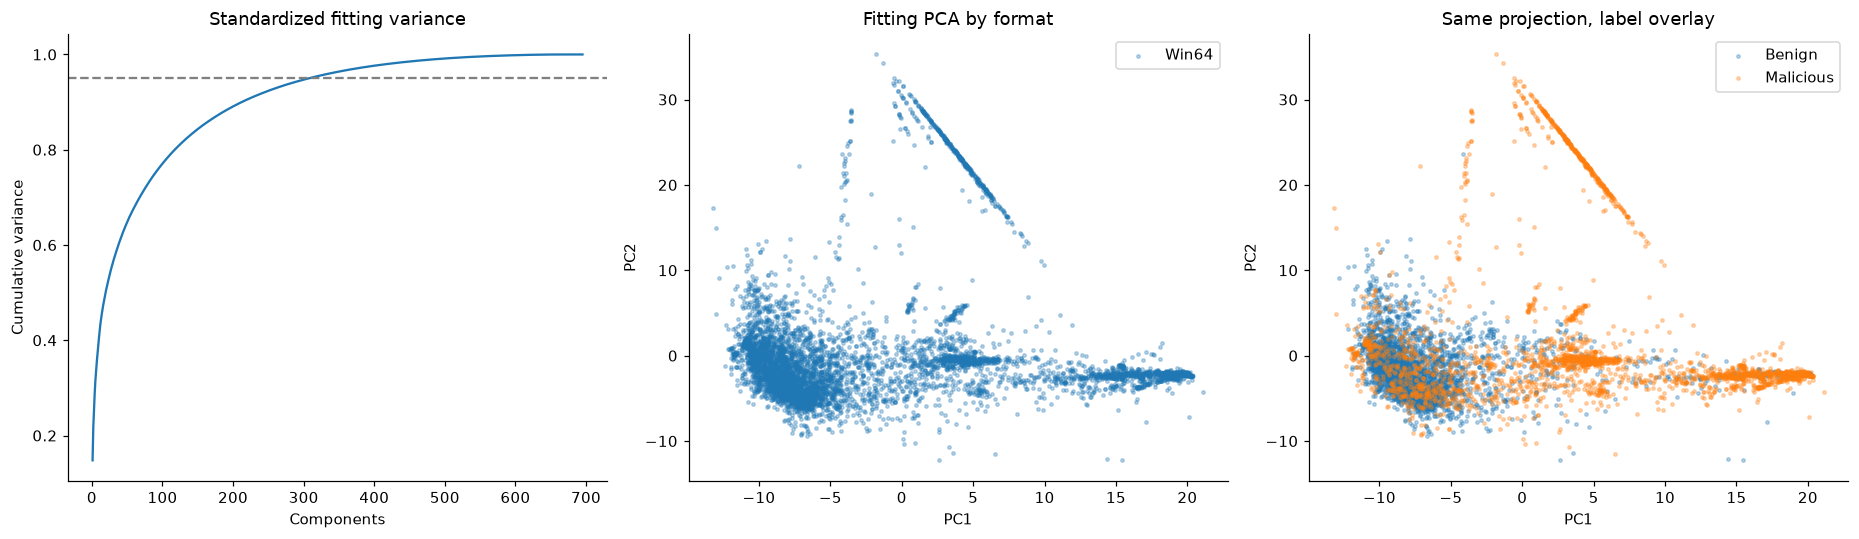

In [60]:
# Plot the PCA projection
# Color the same points by format and label; visual separation is not accuracy.

from multi_label_static_analysis.notebook_steps import plot_pca_structure

plot_pca_structure(explained, coordinates, meta, sample_idx, y, savefig)


In [61]:
# Check the PCA milestone
# Variance retention describes this fitting sample, not future predictive performance.

print("Sampled components needed:", components_needed)
assert np.isfinite(coordinates).all() and np.isclose(explained.variance_ratio.sum(), 1)
print(
    "PASS: PCA fitted only on fitting inputs; variance and loading evidence exported without a classifier."
)


Sampled components needed: {'0.9': 213, '0.95': 308, '0.99': 486}
PASS: PCA fitted only on fitting inputs; variance and loading evidence exported without a classifier.


## 10. Inspect temporal drift

Compare fitting and validation feature samples. KS distance is descriptive here; related files and time dependence limit IID interpretations. Do not tune from held-out labels.

In [62]:
# Sample the validation period
# Choose records by hash without inspecting their labels.

from scipy.stats import ks_2samp

val_order = sorted(
    idx["validation"],
    key=lambda i: hashlib.sha256((str(SEED) + meta.sha256.iloc[i]).encode()).digest(),
)
val_idx = np.array(val_order[:20000])
drift_rows = []


In [63]:
# Measure feature-distribution changes
# KS distance is an effect size here, not an IID significance claim.

for start in range(0, D, 16):
    columns = np.arange(start, min(start + 16, D))
    a = np.asarray(X[np.ix_(sample_idx, columns)])
    b = np.asarray(X[np.ix_(val_idx, columns)])
    for k, j in enumerate(columns):
        aa = a[:, k]
        bb = b[:, k]
        aa = aa[np.isfinite(aa)]
        bb = bb[np.isfinite(bb)]
        distance = (
            ks_2samp(aa, bb, method="asymp").statistic
            if len(aa) and len(bb)
            else np.nan
        )
        drift_rows.append(
            {
                "index": int(j),
                "feature": names[j],
                "group": names[j].split(".")[0],
                "ks_distance": float(distance),
                "fit_median": float(np.median(aa)),
                "validation_median": float(np.median(bb)),
            }
        )


In [64]:
# Export the drift ranking
# Keep temporal drift separate from feature-selection scores.

drift = pd.DataFrame(drift_rows).sort_values("ks_distance", ascending=False)
drift.to_csv(REPORT / "fitting_validation_drift.csv", index=False)
display(drift.head(15))


,index,feature,group,ks_distance,fit_median,validation_median
0,0,general.size,general,0.15445,1.206416e+06,501248.000000
566,566,strings.printable_076,strings,0.13975,9.274918e-03,0.007937
655,655,strings.count.exit,strings,0.13310,5.000000e+00,5.000000
519,519,strings.numstrings,strings,0.12805,3.385000e+03,2611.000000
567,567,strings.printable_077,strings,0.12770,6.314459e-03,0.004956
558,558,strings.printable_068,strings,0.12200,1.109741e-02,0.010151
433,433,byteentropy.entropy_10.bytebin_10,byteentropy,0.12195,3.878556e-04,0.000519
170,170,histogram.byte_163,histogram,0.11880,1.000381e-03,0.001155
168,168,histogram.byte_161,histogram,0.11870,1.102921e-03,0.001253
428,428,byteentropy.entropy_10.bytebin_05,byteentropy,0.11815,1.165134e-03,0.001770


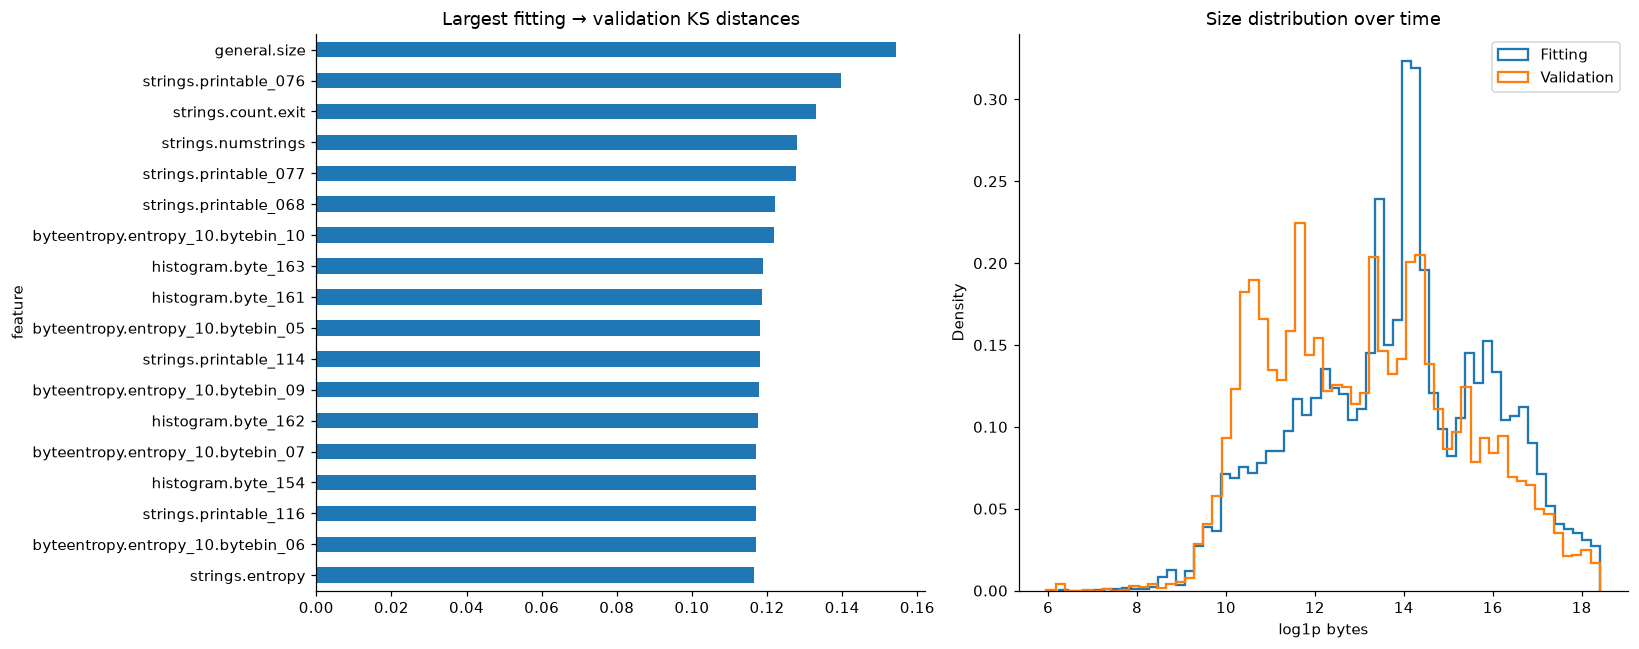

In [65]:
# Plot the largest changes
# These views are descriptive; they do not tune against held-out labels.

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
drift.head(18).sort_values("ks_distance").set_index("feature").ks_distance.plot.barh(
    ax=axes[0], title="Largest fitting → validation KS distances"
)
for split, ii in [("Fitting", sample_idx), ("Validation", val_idx)]:
    axes[1].hist(
        np.log1p(X[ii, 0]), bins=60, density=True, histtype="step", lw=1.5, label=split
    )
axes[1].legend()
axes[1].set(title="Size distribution over time", xlabel="log1p bytes", ylabel="Density")
savefig("09_temporal_feature_drift.png")


In [66]:
# Check drift-analysis boundaries
# Only fitting and validation inputs enter these comparisons.

assert set(meta.iloc[sample_idx].split) == {"fit"} and set(
    meta.iloc[val_idx].split
) == {"validation"}
print(
    "PASS: drift inspection uses fitting/validation inputs only, with no held-out feature ranking."
)


PASS: drift inspection uses fitting/validation inputs only, with no held-out feature ranking.


## 11. Review findings and historical scores

Read the preserved baseline table without loading models. Its earlier APK/PDF/Win64 population differs from the current Win64 analysis. Stop here to review the next proposal step.

In [67]:
# Read the historical score reference
# Read protected score tables only; do not load or recreate a classifier.

verify_score_reference(P.historical)
baseline = pd.read_csv(P.historical / "ember2024_baseline_comparison.csv")
columns = [
    "split",
    "configuration",
    "n",
    "detection_recall",
    "detection_fpr",
    "behavior_micro_f1",
    "behavior_macro_ap",
]
display(baseline[columns])


,split,configuration,n,detection_recall,detection_fpr,behavior_micro_f1,behavior_macro_ap
0,test,research_two_stage,179883,0.724862,0.009919,0.542589,0.519461
1,test,ember2024_ovr_direct,179883,0.854916,0.009363,0.301283,0.381619
2,test,ember2024_ovr_gated,179883,0.854916,0.009363,0.321682,0.377901
3,challenge,research_two_stage,6313,0.301283,NaN,0.017391,0.181428
4,challenge,ember2024_ovr_direct,6313,0.314114,NaN,0.149398,0.153276
5,challenge,ember2024_ovr_gated,6313,0.314114,NaN,0.114943,0.138567


In [68]:
# List unsupported roles
# Keep the data, feature and reference facts together for the written findings.

unsupported = [label for label, ok in zip(LABELS, supported) if not ok]


In [69]:
# Record population and analysis scope
# Keep the data, feature and reference facts together for the written findings.

summary = {
    "milestone": "primary data and feature analysis only",
    "classifiers_trained": 0,
    "serialized_models": 0,
    "raw_rows": quality["raw_rows"],
    "retained_metadata_rows": len(meta),
    "eligible_rows": int(keep.sum()),
    "fitting_rows": len(idx["fit"]),
    "fitting_formats": sorted(meta.iloc[idx["fit"]].file_type.unique().tolist()),
}


In [70]:
# Record feature and label quality
# Keep the data, feature and reference facts together for the written findings.

summary.update(
    {
        "features": D,
        "variable_features": len(variable),
        "constant_features": int(stats.constant.sum()),
        "supported_roles": [label for label, ok in zip(LABELS, supported) if ok],
        "unsupported_roles": unsupported,
        "unannotated_fitting_malware": int((fit & (y == 1) & ~annotated).sum()),
        "duplicate_audit": conflict_summary,
        "tlsH_cross_partition_purges": tlsh_purged,
    }
)


In [71]:
# Record projection and reference provenance
# Keep the data, feature and reference facts together for the written findings.

summary.update(
    {
        "vector_quality": vector_quality,
        "correlation_pairs_098": len(pairs),
        "correlation_pruned_dimensions": len(pruned),
        "correlation_and_PCA_fit_sample_n": len(sample_idx),
        "PCA_components_needed": components_needed,
        "source_records_sha256": source_sha,
        "historical_score_status": score_reference["status"],
    }
)


In [72]:
# Export the analysis summary
# Keep the data, feature and reference facts together for the written findings.

(REPORT / "analysis_summary.json").write_text(json.dumps(summary, indent=2));


In [73]:
# Write concise findings
# The detailed numerical evidence remains in the exported tables.

from multi_label_static_analysis.notebook_readability import format_findings

notes = format_findings(summary, len(mi_idx))
(REPORT / "findings.md").write_text(notes)
display(Markdown(notes))


# Primary analysis findings

- **Population:** 1,286,315 raw rows; 646,079 eligible records; 400,000 fitting records (Win64).
- **Inputs:** 696 named features, including 1 constant fitting column(s); 0 non-finite cells. Independent vector checks: 22 rows.
- **Labels:** 101,312 fitting malware records lack behavior annotations. Unsupported roles: Botnet Agent.
- **Identity quality:** 0 duplicate identities disagree on binary labels; 0 disagree on behavior tags.
- **Exploratory selection:** ANOVA uses all fitting rows; MI uses 6,000. The top-64/128/256 and correlation-pruned sets are proposals, not validated winners.
- **Redundancy and PCA:** 76 sample feature pairs have |r| ≥ 0.98. PCA needs 308 components for 95% of sampled standardized variance.
- **Scope:** historical baseline scores are references only. No classifier was trained or evaluated.

## Review before modeling

1. Keep shared inputs, or inspect Win64-specific PE groups next?
2. Are the role aliases and missing-annotation assumptions defensible?
3. Which candidate subsets and transforms merit a controlled comparison?
4. Should similarity controls include fuzzy/family grouping, and what new evaluation period is available?


In [74]:
# Check the analysis-only contract
# Stop at data understanding; do not advance to supervised modeling.

assert_no_models(ART)
verify_score_reference(P.historical)
print(
    "PASS: primary analysis complete; zero classifier fits, zero saved models, baseline reference verified."
)


PASS: primary analysis complete; zero classifier fits, zero saved models, baseline reference verified.


## Historical reference provenance

The baseline comparison was recovered from the earlier recorded CSV report and checked against the notebook reference table. It was not recomputed. See `results/historical/baseline_score_manifest.json`. Its earlier mixed-format population differs from the current fitting data.